## 4 Image Segmentation 

In [11]:
# ===========================================
#  Imports & Config
# ===========================================
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from PIL import Image

# Replace with your actual email username
username = "kuluri.sarvani"
import hashlib

# Seed from username
username = "kuluri.sarvani"
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
# For reproducibility
RANDOM_STATE = seed


In [12]:
# ===========================================
# Custom Gaussian Mixture Model (GMM)
# ===========================================
class GMM_Custom:
    """
    Gaussian Mixture Model implemented with the EM algorithm.
    """

    def __init__(self, n_components=3, max_iter=100, tol=1e-4, random_state=seed):
        self.n_components = n_components
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = np.random.RandomState(random_state)
        self.means_ = None
        self.covs_ = None
        self.weights_ = None
        self.log_likelihoods_ = []

    def _initialize_params(self, X):
        n_samples, n_features = X.shape
        # Randomly initialize means
        rand_idx = self.random_state.choice(n_samples, self.n_components, replace=False)
        self.means_ = X[rand_idx]
        # Initialize covariances
        self.covs_ = np.array([np.cov(X, rowvar=False)] * self.n_components)
        # Initialize weights
        self.weights_ = np.ones(self.n_components) / self.n_components

    def _gaussian_pdf(self, X, mean, cov):
        n_features = X.shape[1]
        det = np.linalg.det(cov)
        inv = np.linalg.inv(cov)
        norm_const = 1.0 / np.sqrt(((2 * np.pi) ** n_features) * det)
        X_centered = X - mean
        exp_term = np.exp(-0.5 * np.sum(X_centered @ inv * X_centered, axis=1))
        return norm_const * exp_term

    def fit(self, X):
        n_samples, _ = X.shape
        self._initialize_params(X)

        for iteration in range(self.max_iter):
            # E-step
            resp = np.zeros((n_samples, self.n_components))
            for k in range(self.n_components):
                resp[:, k] = self.weights_[k] * self._gaussian_pdf(X, self.means_[k], self.covs_[k])
            resp /= resp.sum(axis=1, keepdims=True)

            # M-step
            Nk = resp.sum(axis=0)
            self.weights_ = Nk / n_samples
            self.means_ = (resp.T @ X) / Nk[:, np.newaxis]
            for k in range(self.n_components):
                X_centered = X - self.means_[k]
                weighted_X = resp[:, k][:, np.newaxis] * X_centered
                self.covs_[k] = (weighted_X.T @ X_centered) / Nk[k]

            # Compute log-likelihood
            log_likelihood = np.sum(np.log(np.sum([
                self.weights_[k] * self._gaussian_pdf(X, self.means_[k], self.covs_[k])
                for k in range(self.n_components)], axis=0)))
            self.log_likelihoods_.append(log_likelihood)

            # Convergence check
            if iteration > 0 and abs(self.log_likelihoods_[-1] - self.log_likelihoods_[-2]) < self.tol:
                break

    def predict(self, X):
        resp = np.zeros((X.shape[0], self.n_components))
        for k in range(self.n_components):
            resp[:, k] = self.weights_[k] * self._gaussian_pdf(X, self.means_[k], self.covs_[k])
        return np.argmax(resp, axis=1)


Image 1 shape: (767, 1000, 3)
Image 2 shape: (1600, 755, 3)


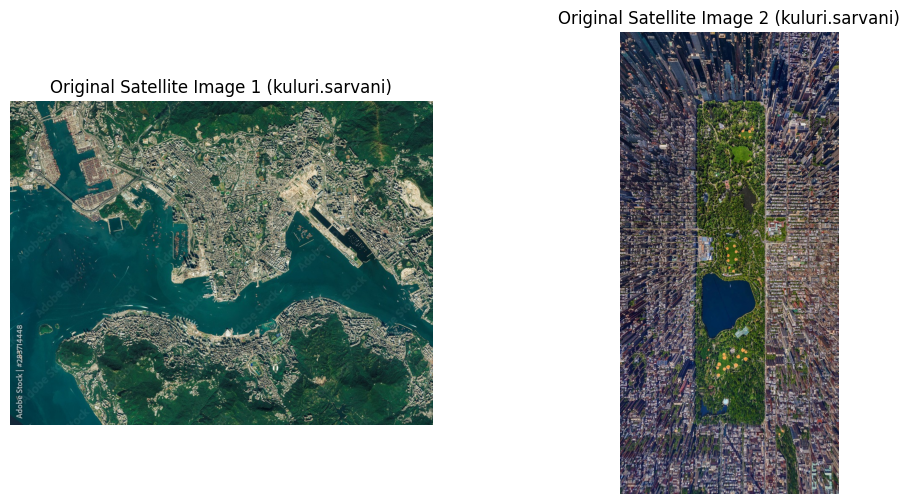

In [ ]:
# ===========================================
# 🖼 Load Satellite Images
# ===========================================
data_path = "/home/rohitha/smai-2ass"

image_files = ["satellite_1.png", "satellite_2.png"]
images = [Image.open(f"{data_path}/{img}") for img in image_files]

# Convert to numpy arrays
images_np = [np.array(img) for img in images]

for i, img in enumerate(images_np):
    print(f"Image {i+1} shape:", img.shape)

# Show original images
fig, axes = plt.subplots(1, 2, figsize=(12,6))
for i, img in enumerate(images_np):
    axes[i].imshow(img)
    axes[i].set_title(f"Original Satellite Image {i+1} ({username})")
    axes[i].axis("off")

# Add watermark
plt.figtext(0.95, 0.02, username, 
            ha='right', va='bottom', 
            fontsize=10, color='gray', alpha=0.7)

plt.tight_layout()
plt.show()


## 4.1 Image Segmentation

In [14]:
# ===========================================
#  Apply GMM for Segmentation (k=3)
# ===========================================
def segment_image(img_np, n_components=3):
    h, w, c = img_np.shape
    X = img_np.reshape(-1, c).astype(np.float64)

    gmm = GMM_Custom(n_components=n_components, max_iter=50, random_state=RANDOM_STATE)
    gmm.fit(X)
    labels = gmm.predict(X)

    # Reshape back to image
    segmented = labels.reshape(h, w)
    return segmented, gmm

# Segment both images
segmented_images = []
gmms = []

for img in images_np:
    seg, gmm = segment_image(img, n_components=3)
    segmented_images.append(seg)
    gmms.append(gmm)


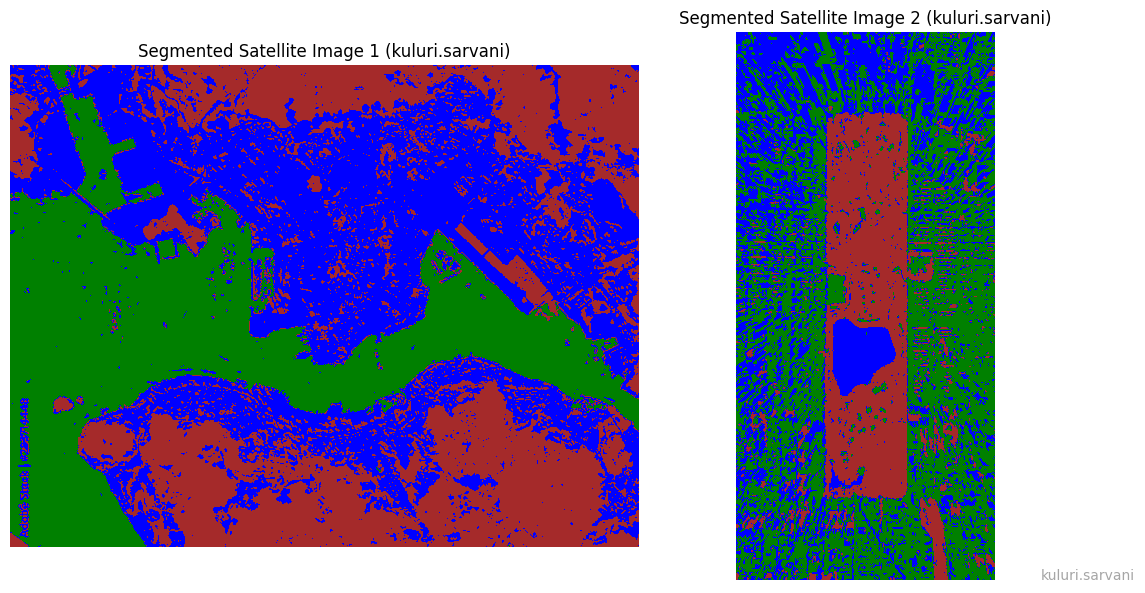

In [21]:
# ===========================================
#  Visualize Segmented Images
# ===========================================
# Define custom colors for Land, Water, Vegetation
cmap = ListedColormap(["green", "blue", "brown"])  

fig, axes = plt.subplots(1, 2, figsize=(12,6))
for i, seg in enumerate(segmented_images):
    axes[i].imshow(seg, cmap=cmap)
    axes[i].set_title(f"Segmented Satellite Image {i+1} ({username})")
    axes[i].axis("off")

# Add watermark
plt.figtext(0.95, 0.02, username, 
            ha='right', va='bottom', 
            fontsize=10, color='gray', alpha=0.7)

plt.tight_layout()
plt.show()


In [16]:
# ===========================================
# 🔹 FIXED Consistent Color Mapping for Segmentation
# ===========================================
import numpy as np

def assign_consistent_colors(gmm, segmented_img):
    """
    Assign consistent colors based on cluster characteristics:
    - Blue for water (high blue component, lower overall brightness)
    - Green for vegetation (high green component)
    - Red for land (higher red component or remaining)
    """
    means = gmm.means_  # Cluster centers in RGB space
    
    # Calculate characteristics for each cluster
    cluster_info = []
    for i, mean_rgb in enumerate(means):
        r, g, b = map(float, mean_rgb)  # ensure scalars, not arrays
        total = r + g + b + 1e-8
        
        # Calculate color dominance (normalized)
        red_ratio = r / total
        green_ratio = g / total  
        blue_ratio = b / total
        
        # Calculate overall brightness
        brightness = np.mean([r, g, b])
        
        # Heuristics
        water_score = blue_ratio * (1.0 - brightness / 255.0)   # bluish + darker → water
        vegetation_score = green_ratio                         # green dominance → vegetation
        land_score = red_ratio + (brightness / 255.0) * 0.3    # reddish or bright → land
        
        cluster_info.append({
            'cluster_id': i,
            'mean_rgb': (r, g, b),
            'brightness': brightness,
            'water_score': water_score,
            'vegetation_score': vegetation_score,
            'land_score': land_score,
            'red_ratio': red_ratio,
            'green_ratio': green_ratio,
            'blue_ratio': blue_ratio
        })
        
        # FIXED: formatting RGB values properly
        print(f"Cluster {i}: RGB=({r:.1f}, {g:.1f}, {b:.1f}), "
              f"Water={water_score:.3f}, Veg={vegetation_score:.3f}, Land={land_score:.3f}")
    
    # Assign colors based on highest scores
    water_cluster = max(cluster_info, key=lambda x: x['water_score'])
    remaining_clusters = [c for c in cluster_info if c['cluster_id'] != water_cluster['cluster_id']]
    
    vegetation_cluster = max(remaining_clusters, key=lambda x: x['vegetation_score'])
    land_cluster = [c for c in cluster_info if c['cluster_id'] 
                    not in [water_cluster['cluster_id'], vegetation_cluster['cluster_id']]][0]
    
    # Create color mapping: 0=Blue(Water), 1=Green(Vegetation), 2=Red(Land)
    color_map = {
        water_cluster['cluster_id']: 0,        # Blue
        vegetation_cluster['cluster_id']: 1,   # Green  
        land_cluster['cluster_id']: 2          # Red
    }
    
    print(f"Final Assignment → Water={water_cluster['cluster_id']}, "
          f"Vegetation={vegetation_cluster['cluster_id']}, Land={land_cluster['cluster_id']}")
    
    # Apply consistent mapping
    consistent_segmented = np.zeros_like(segmented_img)
    for original_cluster, new_color in color_map.items():
        consistent_segmented[segmented_img == original_cluster] = new_color
    
    return consistent_segmented, color_map


# ===========================================
# 🔹 Apply consistent coloring to all segmented images
# ===========================================
consistent_segmented_images = []
color_maps = []

print("="*60)
for i, (seg_img, gmm) in enumerate(zip(segmented_images, gmms)):
    print(f"\nImage {i+1} Analysis:")
    consistent_seg, color_map = assign_consistent_colors(gmm, seg_img)
    consistent_segmented_images.append(consistent_seg)
    color_maps.append(color_map)
print("="*60)



Image 1 Analysis:
Cluster 0: RGB=(4.2, 70.5, 75.6), Water=0.404, Veg=0.469, Land=0.087
Cluster 1: RGB=(118.4, 128.3, 111.4), Water=0.165, Veg=0.358, Land=0.471
Cluster 2: RGB=(22.6, 63.1, 51.5), Water=0.308, Veg=0.460, Land=0.218
Final Assignment → Water=0, Vegetation=2, Land=1

Image 2 Analysis:
Cluster 0: RGB=(115.9, 106.9, 112.5), Water=0.188, Veg=0.319, Land=0.477
Cluster 1: RGB=(37.8, 40.4, 61.1), Water=0.359, Veg=0.290, Land=0.326
Cluster 2: RGB=(60.2, 71.9, 45.2), Water=0.196, Veg=0.406, Land=0.409
Final Assignment → Water=1, Vegetation=2, Land=0


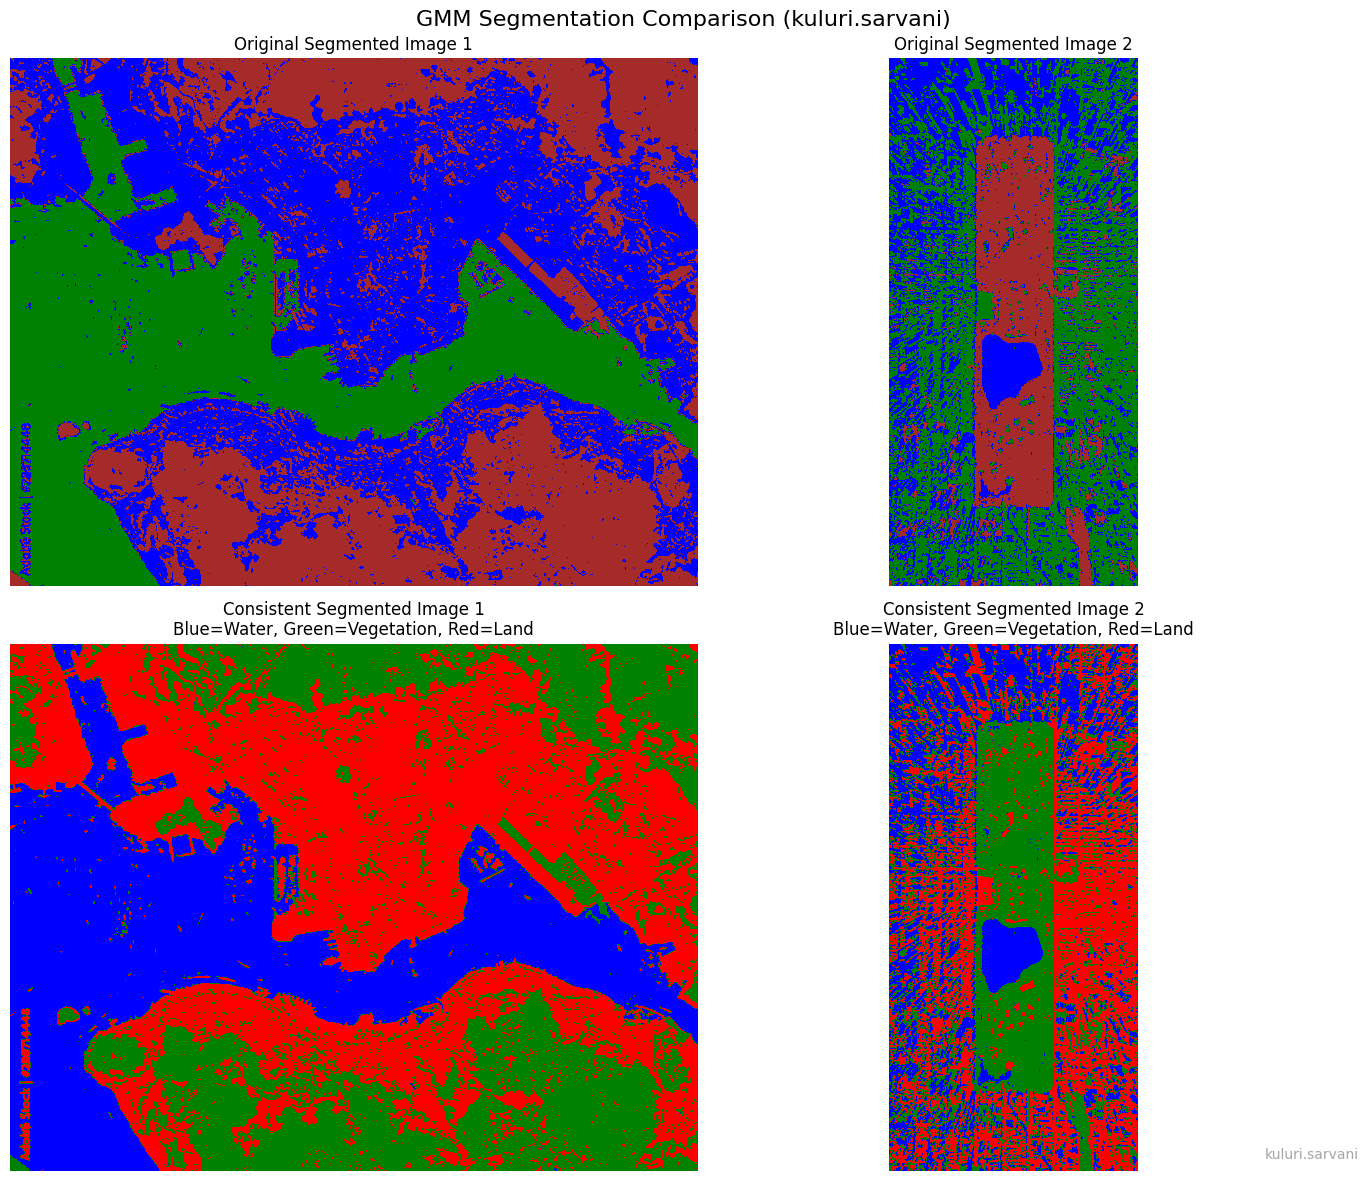


Image 1 Cluster Assignment:
  Water (Blue): Cluster 0
  Vegetation (Green): Cluster 2
  Land (Red): Cluster 1

Image 2 Cluster Assignment:
  Water (Blue): Cluster 1
  Vegetation (Green): Cluster 2
  Land (Red): Cluster 0


In [17]:
# ===========================================
# 🔹 Visualize Consistent Segmented Images
# ===========================================
from matplotlib.colors import ListedColormap

# Define STRICT color scheme: Blue=Water, Green=Vegetation, Red=Land
strict_cmap = ListedColormap(["blue", "green", "red"])  

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Top row: Original segmented images (colors may vary)
for i, seg in enumerate(segmented_images):
    axes[0, i].imshow(seg, cmap=ListedColormap(["green", "blue", "brown"]))
    axes[0, i].set_title(f"Original Segmented Image {i+1}")
    axes[0, i].axis("off")

# Bottom row: Consistent color scheme
for i, consistent_seg in enumerate(consistent_segmented_images):
    axes[1, i].imshow(consistent_seg, cmap=strict_cmap)
    axes[1, i].set_title(f"Consistent Segmented Image {i+1}\nBlue=Water, Green=Vegetation, Red=Land")
    axes[1, i].axis("off")

# Add watermark to the entire figure
plt.figtext(0.95, 0.02, username, 
            ha='right', va='bottom', 
            fontsize=10, color='gray', alpha=0.7)

plt.suptitle(f"GMM Segmentation Comparison ({username})", fontsize=16)
plt.tight_layout()
plt.show()

# Print cluster characteristics for understanding
for i, color_map in enumerate(color_maps):
    print(f"\nImage {i+1} Cluster Assignment:")
    print(f"  Water (Blue): Cluster {[k for k,v in color_map.items() if v==0][0]}")
    print(f"  Vegetation (Green): Cluster {[k for k,v in color_map.items() if v==1][0]}")  
    print(f"  Land (Red): Cluster {[k for k,v in color_map.items() if v==2][0]}")

## Dynamic Visualization Video 

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FFMpegWriter
from PIL import Image

# ===========================================
# 🔹 Function to generate segmentation per iteration
# ===========================================
def segment_with_gmm_iterations(img_np, gmm, max_iter=20, username="rohitha"):
    """
    Runs GMM EM algorithm step by step and yields segmentation + log-likelihood curve at each iteration.
    """
    X = img_np.reshape(-1, 3).astype(np.float64)
    n_samples, n_features = X.shape
    
    gmm._initialize_params(X)
    log_likelihoods = []
    
    for iteration in range(gmm.max_iter):
        # ----- E-step -----
        resp = np.zeros((n_samples, gmm.n_components))
        for k in range(gmm.n_components):
            resp[:, k] = gmm.weights_[k] * gmm._gaussian_pdf(X, gmm.means_[k], gmm.covs_[k])
        resp /= resp.sum(axis=1, keepdims=True)

        # ----- M-step -----
        Nk = resp.sum(axis=0)
        gmm.weights_ = Nk / n_samples
        gmm.means_ = (resp.T @ X) / Nk[:, np.newaxis]
        for k in range(gmm.n_components):
            X_centered = X - gmm.means_[k]
            weighted_X = resp[:, k][:, np.newaxis] * X_centered
            gmm.covs_[k] = (weighted_X.T @ X_centered) / Nk[k] + 1e-6 * np.eye(n_features)

        # ----- Log-likelihood -----
        log_likelihood = np.sum(np.log(np.sum([
            gmm.weights_[k] * gmm._gaussian_pdf(X, gmm.means_[k], gmm.covs_[k])
            for k in range(gmm.n_components)], axis=0)))
        log_likelihoods.append(log_likelihood)

        # ----- Segmentation -----
        labels = np.argmax(resp, axis=1)
        seg_img = gmm.means_[labels].reshape(img_np.shape).astype(np.uint8)

        # Yield current state
        yield iteration, seg_img, log_likelihoods


In [19]:
# ===========================================
# 🔹 Function to generate frames for video
# ===========================================
def create_video(img_np, gmm, output_path="segmentation_video.mp4", username="rohitha"):
    """
    Creates a dynamic video showing:
    - Original image
    - Segmentation per iteration
    - Log-likelihood vs iterations
    """
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    metadata = dict(title="GMM Segmentation", artist=username)
    writer = FFMpegWriter(fps=2, metadata=metadata)

    with writer.saving(fig, output_path, dpi=100):
        for iteration, seg_img, log_likelihoods in segment_with_gmm_iterations(img_np, gmm, username=username):
            axes[0].clear()
            axes[1].clear()
            axes[2].clear()

            # Left: Original
            axes[0].imshow(img_np)
            axes[0].set_title(f"Original Image ({username})")
            axes[0].axis("off")

            # Center: Segmented
            axes[1].imshow(seg_img)
            axes[1].set_title(f"Iteration {iteration} - Segmentation")
            axes[1].axis("off")

            # Right: Log-likelihood plot
            axes[2].plot(range(1, len(log_likelihoods) + 1), log_likelihoods, marker="o", color="blue", label="Log-Likelihood")
            axes[2].set_title("Log-Likelihood vs Iterations")
            axes[2].set_xlabel("Iteration")
            axes[2].set_ylabel("Log-Likelihood")
            axes[2].legend()

            # Watermark
            plt.text(0.95, 0.95, username, ha="right", va="top",
                     transform=axes[2].transAxes, fontsize=10, color="gray", alpha=0.7)

            writer.grab_frame()


 Video saved: segmentation_satellite1.mp4
 Video saved: segmentation_satellite2.mp4


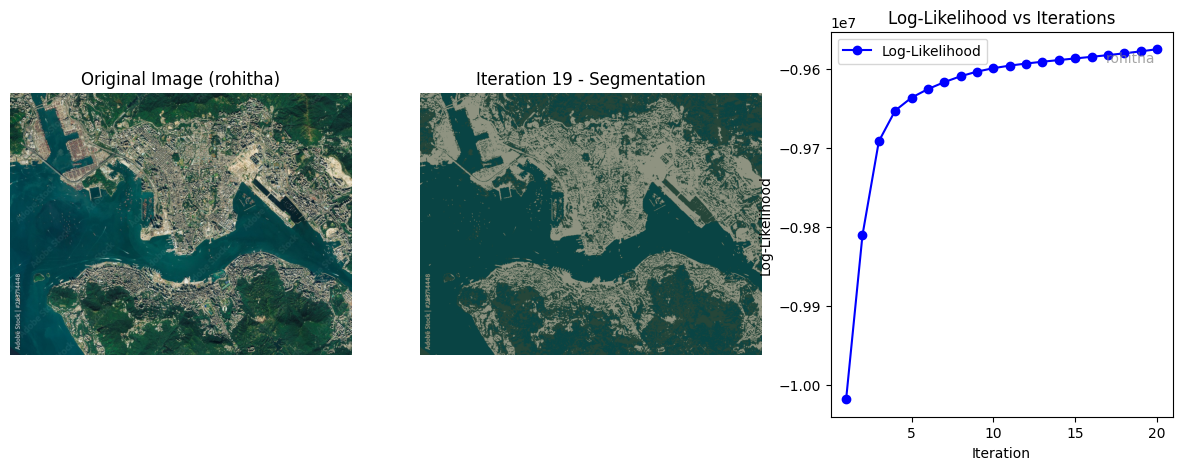

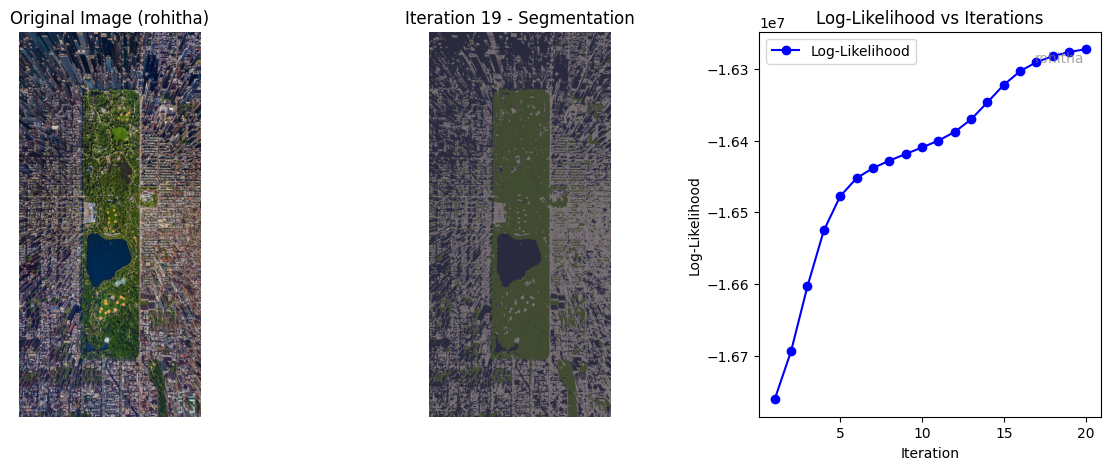

In [ ]:
# ===========================================
# 🔹 Run and save videos for both images
# ===========================================
data_path = "/home/rohitha/smai-2ass"
image_files = ["satellite_1.png", "satellite_2.png"]

for i, img_name in enumerate(image_files, 1):
    img = np.array(Image.open(f"{data_path}/{img_name}"))
    gmm = GMM_Custom(n_components=3, max_iter=20, random_state=seed)

    output_path = f"segmentation_satellite{i}.mp4"
    create_video(img, gmm, output_path=output_path, username="kuluri.sarvani")
    print(f" Video saved: {output_path}")


### segmentation_satellite1.mp4

https://iiithydstudents-my.sharepoint.com/:v:/g/personal/kuluri_sarvani_students_iiit_ac_in/EVM6kjWUggZKnrsAOaORk44Bu8Hj9kyDcLKs08wbzGyNHw?nav=eyJyZWZlcnJhbEluZm8iOnsicmVmZXJyYWxBcHAiOiJPbmVEcml2ZUZvckJ1c2luZXNzIiwicmVmZXJyYWxBcHBQbGF0Zm9ybSI6IldlYiIsInJlZmVycmFsTW9kZSI6InZpZXciLCJyZWZlcnJhbFZpZXciOiJNeUZpbGVzTGlua0NvcHkifX0&e=5lh7Up

### segmentation_satellite2.mp4

https://iiithydstudents-my.sharepoint.com/:v:/g/personal/kuluri_sarvani_students_iiit_ac_in/ETrPqoYHjClFpA7FNsxIl_wB-kCHOwYvEa_gtTVtWadLMg?nav=eyJyZWZlcnJhbEluZm8iOnsicmVmZXJyYWxBcHAiOiJPbmVEcml2ZUZvckJ1c2luZXNzIiwicmVmZXJyYWxBcHBQbGF0Zm9ybSI6IldlYiIsInJlZmVycmFsTW9kZSI6InZpZXciLCJyZWZlcnJhbFZpZXciOiJNeUZpbGVzTGlua0NvcHkifX0&e=x2e8R4